# Fourier Series — Interactive Analysis and Synthesis

**Topic 3: Spectrum Representation** · Digital Signal Processing for Sound and Music

Explore how a periodic waveform is reconstructed by adding harmonically related sinusoids. This notebook is inspired by Georgia Tech's **DSPFirst FourierSeriesDemo** (`fseriesdemo`), which lets the user select square, sawtooth, triangle, or rectified sinusoidal waveforms and change the number of Fourier-series coefficients.

**What you will do:**
1. Select a periodic waveform and change the number of harmonics in its Fourier-series reconstruction.
2. Compare the target signal and reconstructed signal in the time domain.
3. Inspect the **magnitude and phase** of the complex Fourier-series coefficients.
4. Isolate an individual harmonic and observe its contribution.
5. Explore the **Gibbs phenomenon** and listen to the original/reconstructed sounds.

Only **NumPy** and **Matplotlib** are required for the calculations and plots. The interactive controls additionally require **ipywidgets** (`pip install ipywidgets` if needed). The notebook still runs without it, showing a static demonstration.

**References:** [DSPFirst FourierSeriesDemo](https://dspfirst.gatech.edu/matlab/#fseriesdemo) · *Topic 3: Spectrum Representation*, sections **3.3, 3.4, and 3.6** (provided lecture notes).

## 1 · Fourier analysis and synthesis

Let $x(t)$ be periodic with period $T_0$ and fundamental frequency $f_0=1/T_0$. Its **complex Fourier series** is

$$
\boxed{x(t)=\sum_{k=-\infty}^{\infty} a_k\,e^{j2\pi kf_0t}}
$$

where the **Fourier coefficient** of harmonic $k$ is calculated by integration over **one period**:

$$
\boxed{a_k=\frac{1}{T_0}\int_{0}^{T_0} x(t)\,e^{-j2\pi kf_0t}\,dt}
$$

- **Fourier analysis**: obtain the complex coefficients $a_k$ from the waveform $x(t)$.
- **Fourier synthesis**: obtain a waveform by adding harmonic terms defined by the coefficients $a_k$.

For a **real-valued signal**, $a_{-k}=a_k^*$, so the reconstruction using harmonics up to $K$ becomes

$$
\boxed{\hat x_K(t)=a_0+2\sum_{k=1}^{K}|a_k|\cos(2\pi kf_0t+\angle a_k)}.
$$

The **DC** coefficient $a_0$ is the average value; the $k$th positive-frequency coefficient has magnitude $|a_k|$ and phase $\angle a_k$. The corresponding real sinusoid has amplitude $2|a_k|$.

**Important distinction:** the infinite series is a mathematical representation; a finite sum ($K<\infty$) is generally an **approximation**. At jumps, the series converges to the average of the left- and right-hand limits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Fixed number of samples used for the numerical integration over ONE period.
# 8192 samples is enough for the harmonics displayed here.
M = 8192
MAX_K = 40
WAVEFORMS = (
    'Square wave',
    'Sawtooth',
    'Triangle',
    'Half-wave rectified sine',
    'Full-wave rectified sine',
    'Rectangular pulse',
)

print('NumPy and Matplotlib ready.')

NumPy and Matplotlib ready.


## 2 · Define the waveforms and calculate their Fourier coefficients

Each signal below is evaluated at the **normalized phase** $u=t/T_0\pmod 1$. This makes the Fourier coefficients independent of the chosen fundamental frequency $f_0$; changing $f_0$ only changes the horizontal scale in seconds and the frequencies in hertz.

The Fourier integral is approximated by an equally spaced sum over one period:

$$
a_k\approx\frac{1}{M}\sum_{n=0}^{M-1}x[n]e^{-j2\pi kn/M}.
$$

This is exactly the normalized **DFT of one period**. It is used here as a numerical tool to estimate continuous-time Fourier-series coefficients; we are **not** claiming that a finite DFT and an infinite Fourier series are identical.

In [2]:
def waveform(u, kind='Square wave', duty=0.30):
    """Evaluate a periodic waveform for phase u (period = 1, any real u)."""
    u = np.mod(np.asarray(u, dtype=float), 1.0)
    if kind == 'Square wave':
        return np.where(u < 0.5, 1.0, -1.0)
    if kind == 'Sawtooth':
        return 2.0*u - 1.0
    if kind == 'Triangle':
        return 1.0 - 4.0*np.abs(u - 0.5)
    if kind == 'Half-wave rectified sine':
        return np.maximum(np.sin(2*np.pi*u), 0.0)
    if kind == 'Full-wave rectified sine':
        return np.abs(np.sin(2*np.pi*u))
    if kind == 'Rectangular pulse':
        return np.where(u < duty, 1.0, 0.0)
    raise ValueError(f'Unknown waveform: {kind}')


def fourier_coefficients(kind, Kmax=MAX_K, shift=0.0, duty=0.30, M=M):
    """Return a_k for all integer k=-Kmax,...,Kmax by sampling one period.

    shift is a fraction of the fundamental period T0.
    """
    if 2*Kmax >= M:
        raise ValueError('M must be sufficiently large compared with Kmax.')
    u = np.arange(M) / M
    samples = waveform(u - shift, kind, duty=duty)
    # DFT convention: X[k] = sum_n x[n] exp(-j*2*pi*k*n/M)
    fft_coeffs = np.fft.fft(samples) / M
    k = np.arange(-Kmax, Kmax + 1)
    return k, fft_coeffs[np.mod(k, M)]


def synthesize(t, f0, k, a, K):
    """Fourier synthesis of a real-valued signal with harmonics -K,...,+K."""
    if not (0 <= K <= max(k)):
        raise ValueError('K must be between 0 and max(k).')
    a0 = float(np.real(a[k == 0][0]))
    if K == 0:
        return np.full_like(np.asarray(t, dtype=float), a0)
    pos = (k >= 1) & (k <= K)
    kp = k[pos]
    ap = a[pos]
    # Negative-frequency terms are the complex conjugates of positive ones.
    return a0 + 2*np.real(np.sum(
        ap[:, None] * np.exp(1j*2*np.pi*(kp[:, None]*f0)*np.asarray(t)[None, :]),
        axis=0))

# Sanity check: a real waveform must have conjugate-symmetric coefficients.
k_test, a_test = fourier_coefficients('Square wave')
assert np.allclose(a_test, np.conj(a_test[::-1]), atol=1e-12)
print('Computed coefficients over one period; conjugate symmetry verified.')

Computed coefficients over one period; conjugate symmetry verified.


## 3 · Interactive Fourier-series demo

Change the parameters and observe all plots update together. The **Play** button (when ipywidgets is installed) adds harmonics one at a time, like the DSPFirst demo.

**Controls**
- **Waveform**: square, sawtooth, triangle, half-/full-wave rectified sine, or rectangular pulse.
- **$K$**: keep harmonics $k=-K,\dots,K$ (and DC). A value $K=0$ gives only the average.
- **$f_0$**: fundamental frequency in hertz; the $k$th harmonic is at $kf_0$.
- **Time shift**: shift the entire waveform by a fraction of $T_0$. The magnitude spectrum stays the same, while the phase changes.
- **Duty cycle**: used only for the rectangular pulse.
- **Highlighted harmonic**: draw one of the sinusoids that contributes to the reconstruction.

**How to read the figure:** the original and reconstructed waveforms are shown in the top plot. The middle plots display the **two-sided magnitude and phase spectra**. Blue stems are included in the reconstruction; gray stems are not. Phase values for coefficients close to zero are hidden because their phase is unstable and not informative.

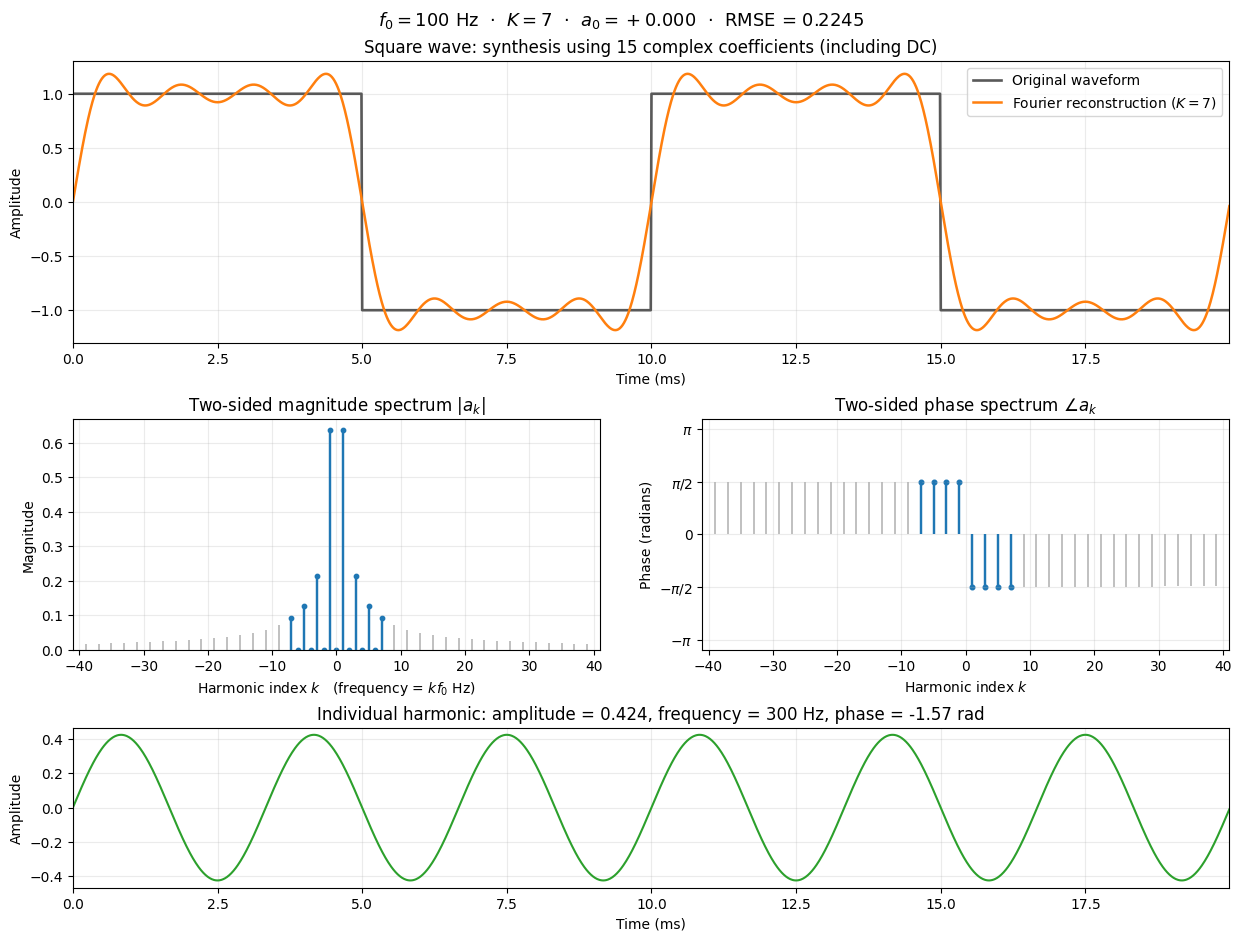

In [3]:
def plot_fourier_demo(kind='Square wave', K=7, f0=100.0, shift=0.0,
                      duty=0.30, highlighted=3, show_harmonic=True):
    K = int(K)
    highlighted = int(highlighted)
    k, a = fourier_coefficients(kind, MAX_K, shift=shift, duty=duty)
    # Show two periods. A normalized time axis (cycles) also remains readable
    # when f0 is changed, so we display both cycles and milliseconds.
    cycles = np.linspace(0.0, 2.0, 1600, endpoint=False)
    t = cycles/f0
    original = waveform(cycles - shift, kind, duty)
    rebuilt = synthesize(t, f0, k, a, K)

    fig = plt.figure(figsize=(12.3, 9.3), constrained_layout=True)
    gs = fig.add_gridspec(3, 2, height_ratios=[2.2, 1.8, 1.25])
    ax_wave = fig.add_subplot(gs[0, :])
    ax_mag = fig.add_subplot(gs[1, 0])
    ax_phase = fig.add_subplot(gs[1, 1])
    ax_h = fig.add_subplot(gs[2, :])

    time_ms = t*1000.0
    ax_wave.plot(time_ms, original, color='0.35', lw=1.9, label='Original waveform')
    ax_wave.plot(time_ms, rebuilt, color='C1', lw=1.8,
                 label=f'Fourier reconstruction ($K={K}$)')
    ax_wave.set_title(f'{kind}: synthesis using {2*K+1} complex coefficients (including DC)')
    ax_wave.set_xlabel('Time (ms)')
    ax_wave.set_ylabel('Amplitude')
    ax_wave.grid(alpha=0.25)
    ax_wave.legend(loc='upper right')
    ax_wave.set_xlim(time_ms[0], time_ms[-1])

    included = np.abs(k) <= K
    ax_mag.vlines(k[~included], 0, np.abs(a[~included]), color='0.72', lw=1.25)
    ax_mag.vlines(k[included], 0, np.abs(a[included]), color='C0', lw=1.75)
    ax_mag.scatter(k[included], np.abs(a[included]), color='C0', s=10)
    ax_mag.set_title(r'Two-sided magnitude spectrum $|a_k|$')
    ax_mag.set_xlabel(r'Harmonic index $k$   (frequency = $kf_0$ Hz)')
    ax_mag.set_ylabel('Magnitude')
    ax_mag.set_xlim(-MAX_K-1, MAX_K+1)
    ax_mag.set_ylim(bottom=0)
    ax_mag.grid(alpha=0.25)

    # Only display phase for coefficients with meaningful magnitude.
    threshold = max(1e-4, float(np.max(np.abs(a)))*0.003)
    present = np.abs(a) > threshold
    ax_phase.vlines(k[present & ~included], 0, np.angle(a[present & ~included]),
                    color='0.72', lw=1.25)
    ax_phase.vlines(k[present & included], 0, np.angle(a[present & included]),
                    color='C0', lw=1.75)
    ax_phase.scatter(k[present & included], np.angle(a[present & included]),
                     color='C0', s=11)
    ax_phase.set_title(r'Two-sided phase spectrum $\angle a_k$')
    ax_phase.set_xlabel(r'Harmonic index $k$')
    ax_phase.set_ylabel('Phase (radians)')
    ax_phase.set_ylim(-np.pi-0.3, np.pi+0.3)
    ax_phase.set_xlim(-MAX_K-1, MAX_K+1)
    ax_phase.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
                        [r'$-\pi$', r'$-\pi/2$', '0', r'$\pi/2$', r'$\pi$'])
    ax_phase.grid(alpha=0.25)

    a_h = a[k == highlighted][0]
    term = 2*np.real(a_h*np.exp(1j*2*np.pi*highlighted*f0*t))
    if show_harmonic:
        ax_h.plot(time_ms, term, color='C2', label=f'Harmonic {highlighted}')
        ax_h.set_title(f'Individual harmonic: amplitude = {2*abs(a_h):.3f}, '
                       f'frequency = {highlighted*f0:.0f} Hz, '
                       f'phase = {np.angle(a_h):+.2f} rad')
    else:
        ax_h.plot(time_ms, original-rebuilt, color='C2', label='Residual')
        ax_h.set_title(r'Reconstruction error $x(t)-\hat{x}_K(t)$')
    ax_h.set_xlabel('Time (ms)')
    ax_h.set_ylabel('Amplitude')
    ax_h.set_xlim(time_ms[0], time_ms[-1])
    ax_h.grid(alpha=0.25)

    # RMSE, measured on one period (discrete approximation).
    t_one = (np.arange(M)/M)/f0
    ref_one = waveform(np.arange(M)/M - shift, kind, duty)
    approx_one = synthesize(t_one, f0, k, a, K)
    rmse = np.sqrt(np.mean((ref_one-approx_one)**2))
    fig.suptitle(f'$f_0={f0:.0f}$ Hz  ·  $K={K}$  ·  '
                 f'$a_0={np.real(a[k==0][0]):+.3f}$  ·  '
                 f'RMSE = {rmse:.4f}', fontsize=13)
    plt.show()

# Show a demonstration immediately, even without interactive widgets.
plot_fourier_demo(kind='Square wave', K=7, highlighted=3)

In [4]:
# Interactive controls. This cell also works as a static notebook if
# ipywidgets has not been installed in the Jupyter environment.
try:
    import ipywidgets as widgets
    from IPython.display import display
except ImportError:
    widgets = None
    print('ipywidgets is not installed. Run: %pip install ipywidgets')
    print('The static demonstration above still works.')

if widgets is not None:
    kind_widget = widgets.Dropdown(options=WAVEFORMS, value='Square wave',
                                   description='Waveform:', style={'description_width': 'initial'})
    k_widget = widgets.IntSlider(value=7, min=0, max=MAX_K, step=1,
                                 description='Harmonics K:', continuous_update=False,
                                 style={'description_width': 'initial'})
    f0_widget = widgets.FloatSlider(value=100, min=50, max=300, step=25,
                                    description='Fundamental f₀:', continuous_update=False,
                                    style={'description_width': 'initial'})
    shift_widget = widgets.FloatSlider(value=0.0, min=0.0, max=0.95, step=0.05,
                                       description='Time shift / T₀:', continuous_update=False,
                                       style={'description_width': 'initial'})
    duty_widget = widgets.FloatSlider(value=0.30, min=0.10, max=0.90, step=0.05,
                                      description='Pulse duty cycle:', continuous_update=False,
                                      style={'description_width': 'initial'})
    highlighted_widget = widgets.IntSlider(value=3, min=1, max=MAX_K, step=1,
                                           description='Highlight k:', continuous_update=False,
                                           style={'description_width': 'initial'})
    show_widget = widgets.Checkbox(value=True, description='Show individual harmonic (otherwise show error)')
    play_widget = widgets.Play(value=7, min=0, max=MAX_K, step=1, interval=450,
                               description='Animate K')
    widgets.jslink((play_widget, 'value'), (k_widget, 'value'))

    interactive_chart = widgets.interactive_output(plot_fourier_demo, {
        'kind': kind_widget, 'K': k_widget, 'f0': f0_widget,
        'shift': shift_widget, 'duty': duty_widget,
        'highlighted': highlighted_widget, 'show_harmonic': show_widget,
    })
    display(widgets.VBox([
        widgets.HBox([kind_widget, f0_widget]),
        widgets.HBox([play_widget, k_widget]),
        widgets.HBox([shift_widget, duty_widget]),
        widgets.HBox([highlighted_widget, show_widget]),
        interactive_chart,
    ]))

## 4 · Listening comparison

Use **the current interactive settings** (when the widgets are available) to synthesize 0.7 seconds of the original waveform and its finite-harmonic reconstruction. After changing the controls, **run the cell again** to listen to the new sound.

Some waveforms have sharp discontinuities (square or sawtooth). A finite number of harmonics rounds these transitions and may create ringing. The playback is normalized to a safe level; the oscillator starts and ends with a short fade to avoid clicks. The audio sampling rate is 44,100 Hz and the highest available harmonic stays below Nyquist for the selected $f_0$ range.

In [5]:
# Read controls if the interactive panel is available; otherwise use defaults.
if widgets is None:
    listen_kind, listen_K, listen_f0, listen_shift, listen_duty = (
        'Square wave', 7, 100.0, 0.0, 0.30)
else:
    listen_kind, listen_K, listen_f0, listen_shift, listen_duty = (
        kind_widget.value, k_widget.value, f0_widget.value,
        shift_widget.value, duty_widget.value)

fs_audio = 44100
duration = 0.7
t_audio = np.arange(int(duration * fs_audio)) / fs_audio
ks, aks = fourier_coefficients(listen_kind, MAX_K,
                               shift=listen_shift, duty=listen_duty)
original_audio = waveform(listen_f0*t_audio-listen_shift, listen_kind, listen_duty)
reconstruction_audio = synthesize(t_audio, listen_f0, ks, aks, listen_K)

# Very short fade-in/out to prevent playback clicks.
fade_length = int(0.005*fs_audio)
fade = np.ones_like(t_audio)
fade[:fade_length] = np.linspace(0,1,fade_length)
fade[-fade_length:] = np.linspace(1,0,fade_length)
original_audio = 0.65*fade*original_audio
reconstruction_audio = 0.65*fade*reconstruction_audio

print(f'{listen_kind}; f0 = {listen_f0:.0f} Hz; K = {listen_K}')
print('Original:')
display(Audio(original_audio, rate=fs_audio, normalize=False))
print('Finite Fourier reconstruction:')
display(Audio(reconstruction_audio, rate=fs_audio, normalize=False))

Square wave; f0 = 100 Hz; K = 7
Original:


Finite Fourier reconstruction:


## 5 · Gibbs phenomenon: why do oscillations remain near a jump?

A square wave has discontinuities. Even when the number of harmonics grows, the finite Fourier reconstruction exhibits oscillations near these jumps. The oscillating region gets narrower, but the **maximum overshoot** approaches about **9% of the jump height** rather than disappearing.

The curve below overlays several reconstructions. Zoom in around the jump at $t=0$ to see what changes when adding harmonics.

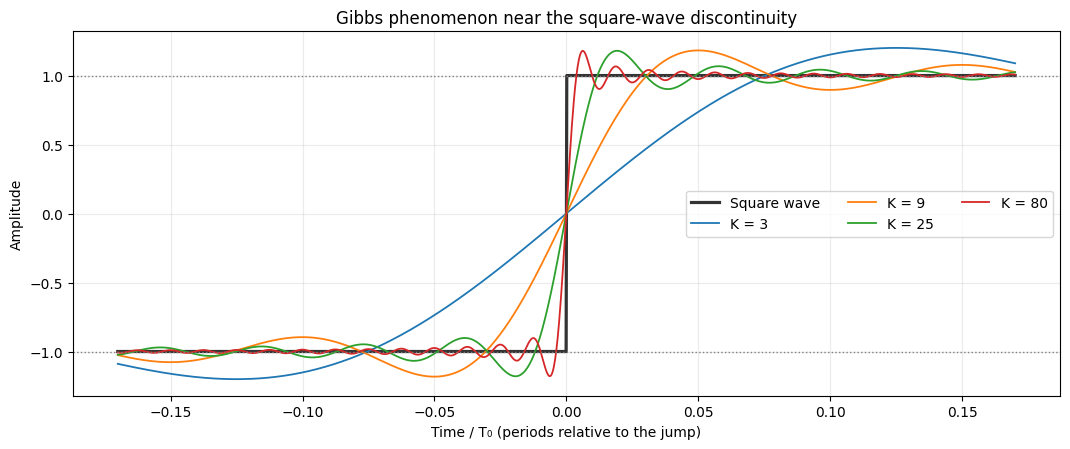

In [6]:
# Square-wave Gibbs phenomenon near t=0: show both sides of the jump.
ks, aks = fourier_coefficients('Square wave', Kmax=80)
cycles_gibbs = np.linspace(-0.17, 0.17, 1400)
t_gibbs = cycles_gibbs/100.0

fig, ax = plt.subplots(figsize=(10.8, 4.6))
ax.plot(cycles_gibbs, waveform(cycles_gibbs, 'Square wave'),
        color='0.20', lw=2.3, label='Square wave')
for Kcur in (3, 9, 25, 80):
    ax.plot(cycles_gibbs, synthesize(t_gibbs, 100.0, ks, aks, Kcur),
            label=f'K = {Kcur}', lw=1.3)
ax.axhline(1, color='0.5', linestyle=':', linewidth=1)
ax.axhline(-1, color='0.5', linestyle=':', linewidth=1)
ax.set_title('Gibbs phenomenon near the square-wave discontinuity')
ax.set_xlabel('Time / T₀ (periods relative to the jump)')
ax.set_ylabel('Amplitude')
ax.grid(alpha=0.25)
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

## 6 · Small exercises

**A. Harmonic count.** Select a square wave. Compare $K=1,3,10,40$: how does the waveform improve, and what remains near the discontinuities? What does the magnitude spectrum tell you about even and odd harmonics?

**B. Spectrum decay.** Compare square and triangular waves. Which waveform has faster-decaying Fourier coefficients? How does the decay explain the smoothness of the reconstructed signal?

**C. Rectification.** Try half-wave and full-wave rectified sinusoids. Which harmonics are present? Why does the full-wave signal contain only even multiples of the original sine frequency $f_0$ (aside from DC)?

**D. Phase and time shift.** Shift the square or sawtooth by $0.25T_0$. Does $|a_k|$ change? What happens to $\angle a_k$? Verify that the coefficients obey $a_k^{\mathrm{shifted}} = a_k e^{-j2\pi k(0.25)}$.

**E. Duty cycle.** Select *Rectangular pulse* and vary its duty cycle. Look at the changing DC component and the positions of small / zero harmonic coefficients.

### Key takeaways

- The **fundamental frequency** $f_0$ sets the spacing between spectral lines: $f_k=kf_0$.
- The **complex amplitude** $a_k$ contains both magnitude and phase.
- The number of harmonics $K$ controls the detail in the reconstruction; a jump needs many high harmonics.
- For a **real signal**, the negative-frequency coefficients are conjugate copies of the positive-frequency coefficients.
- **Fourier analysis** computes coefficients; **Fourier synthesis** uses them to reconstruct the signal.